# Identificar fronteras no lineales

In [49]:
from sklearn.datasets import make_circles, make_blobs

In [2]:
X, Y = make_circles(100, factor=.1, noise=.1)

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.svm import SVC

In [37]:
def plt_svc(model, ax=None, plot_support=True):
    """Plot de la función de decisión para una clasificación en 2D con SVC"""
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    ##Generamos la parrila de puntos para evaluar el modelo
    xx = np.linspace(xlim[0], xlim[1], 30)
    yy = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(yy,xx)
    
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    
    ##Representamos las fronteras y los márgenes del SVC
    ax.contour(X,Y,P, colors="k", levels=[-1,0,1], alpha = 0.5, linestyles=["--", "-", "--"])
    
    
    
    if plot_support:
        ax.scatter(model.support_vectors_[:,0], 
                   model.support_vectors_[:,1], 
                   s=300, linewidth=1, facecolors = "blue");
    
    
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    

In [38]:
def plot_svm(N=10, ax=None):
    X, Y = make_blobs(n_samples=200, centers=2, random_state=0, cluster_std=0.6)
    
    X = X[:N]
    Y = Y[:N]
    model = SVC(kernel="linear", C=1E10)
    model.fit(X,Y)
    
    ax = ax or plt.gca()
    ax.scatter(X[:,0], X[:,1], c=Y, s = 50, cmap="autumn")
    ax.set_xlim(-1,4)
    ax.set_ylim(-1,6)
    plt_svc(model, ax)
    


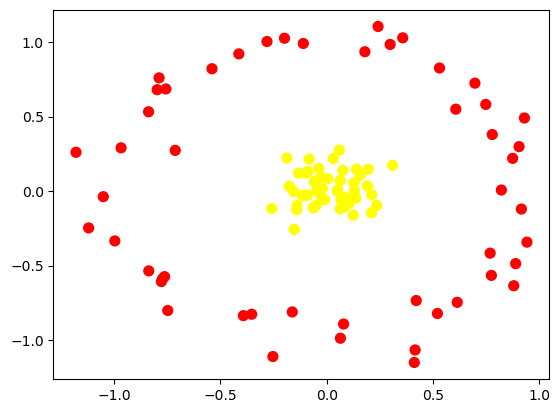

In [39]:
plt.scatter(X[:,0], X[:,1], c=Y, s=50, cmap="autumn")

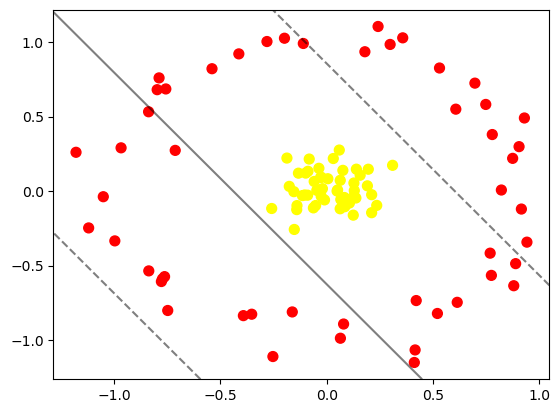

In [40]:
plt.scatter(X[:,0], X[:,1], c=Y, s=50, cmap="autumn")
plt_svc(SVC(kernel="linear").fit(X,Y), plot_support=False)

In [41]:
r = np.exp(-(X**2).sum(1))

In [42]:
r

array([0.40395248, 0.99767053, 0.91405601, 0.94218051, 0.98341149,
       0.36080046, 0.99249256, 0.27292197, 0.30816703, 0.99067656,
       0.37750073, 0.98238309, 0.99635481, 0.97556092, 0.3722095 ,
       0.40377547, 0.47255962, 0.98206488, 0.4455397 , 0.33069427,
       0.99098393, 0.36657983, 0.99112402, 0.96832001, 0.39287927,
       0.42591104, 0.9748264 , 0.33720955, 0.96508632, 0.55832906,
       0.99085314, 0.23247777, 0.38156748, 0.96305648, 0.51150749,
       0.34727909, 0.98599924, 0.42653436, 0.48807856, 0.26827231,
       0.9931609 , 0.50960998, 0.95250408, 0.36420168, 0.37307101,
       0.33145632, 0.95992334, 0.9885071 , 0.27830063, 0.99137762,
       0.30555634, 0.37008488, 0.96467249, 0.33295831, 0.9980592 ,
       0.35233432, 0.94835267, 0.97628988, 0.44789598, 0.98100287,
       0.9365305 , 0.95588578, 0.99932104, 0.40776366, 0.93761874,
       0.88199772, 0.97121138, 0.97526299, 0.46577622, 0.97590347,
       0.3309455 , 0.98327749, 0.40156296, 0.37513184, 0.35834

In [43]:
from mpl_toolkits import mplot3d

In [44]:
def plot_3D(elev=30, azim=30, X=X, Y=Y, r=r):
    ax = plt.subplot(projection="3d")
    ax.scatter3D(X[:,0], X[:,1], r, c=Y, s= 50, cmap="autumn")
    ax.view_init(elev=elev, azim=azim)

    ax.set_xlabel("x[0]")
    ax.set_ylabel("y[1]")
    ax.set_zlabel("r")

In [45]:
from ipywidgets import interact, fixed

In [46]:
interact(plot_3D, elev=[-90,-60,-30,0,30,60,90], 
         azim=[-180,-150,-120,-90,-60,-30,0,30,60,90,120,150,180], 
         X = fixed(X), Y = fixed(Y), r = fixed(r))

interactive(children=(Dropdown(description='elev', index=4, options=(-90, -60, -30, 0, 30, 60, 90), value=30),…

<function __main__.plot_3D(elev=30, azim=30, X=array([[ 9.04198764e-01,  2.98131905e-01],
       [ 4.82919557e-02,  2.74145342e-04],
       [-1.52945425e-01, -2.57819959e-01],
       [ 1.95117410e-01,  1.46586476e-01],
       [-6.30133907e-02, -1.12946700e-01],
       [-4.13733686e-01,  9.21007409e-01],
       [ 7.17619796e-02, -4.88464680e-02],
       [-2.53517448e-01, -1.11098976e+00],
       [ 8.79246298e-01, -6.35640835e-01],
       [-2.90873003e-02,  9.23098487e-02],
       [-7.77957267e-01, -6.07425120e-01],
       [ 1.06344313e-01, -8.04041212e-02],
       [-1.08020698e-02, -5.94572662e-02],
       [-3.72196432e-02,  1.52831169e-01],
       [-8.37265172e-01, -5.35990158e-01],
       [ 1.79093864e-01,  9.35319043e-01],
       [ 7.78222494e-01,  3.79422061e-01],
       [ 6.27717856e-02, -1.18985728e-01],
       [-3.53201948e-01, -8.26872007e-01],
       [-1.05124590e+00, -3.79872453e-02],
       [-2.52240509e-02,  9.17644349e-02],
       [ 9.41197928e-01, -3.43053087e-01],
       

In [47]:
rbf = SVC(kernel="rbf", C=1E6)
rbf.fit(X,Y)

,C,1000000.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


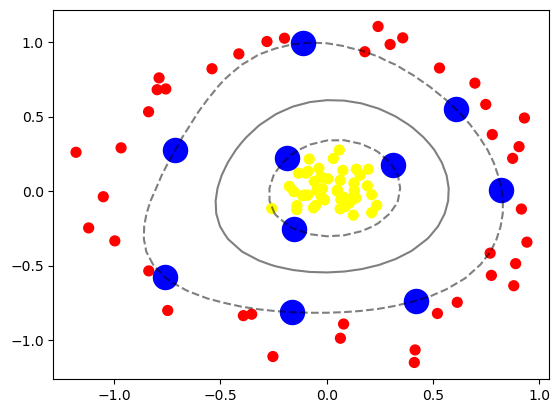

In [48]:
plt.scatter(X[:,0], X[:,1], c=Y, s=50, cmap="autumn")
plt_svc(rbf)
plt.scatter(rbf.support_vectors_[:,0], rbf.support_vectors_[:,1], s=300, lw=1, facecolors="none")

## Ajustar los parametros de SVM

In [62]:
X, Y = make_blobs(n_samples=100, centers=2, random_state=0, cluster_std=1.2)

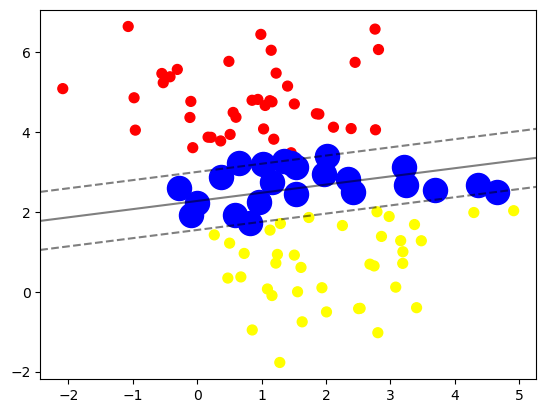

In [63]:
plt.scatter(X[:,0], X[:,1], c = Y, s=50, cmap="autumn")
model = SVC(kernel="linear", C=10)
model.fit(X,Y)
plt_svc(model)

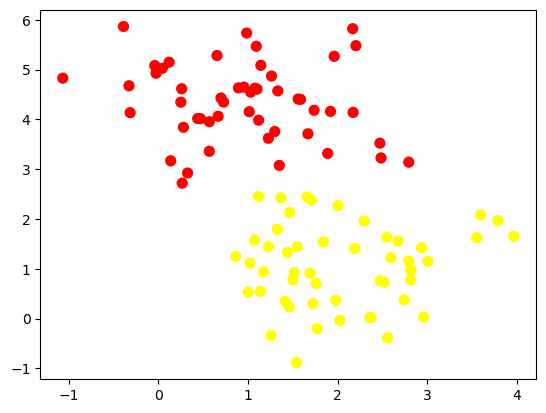

In [59]:
X, Y = make_blobs(n_samples=100, centers=2, random_state=0, cluster_std=0.8)
plt.scatter(X[:,0], X[:,1], c = Y, s=50, cmap="autumn")

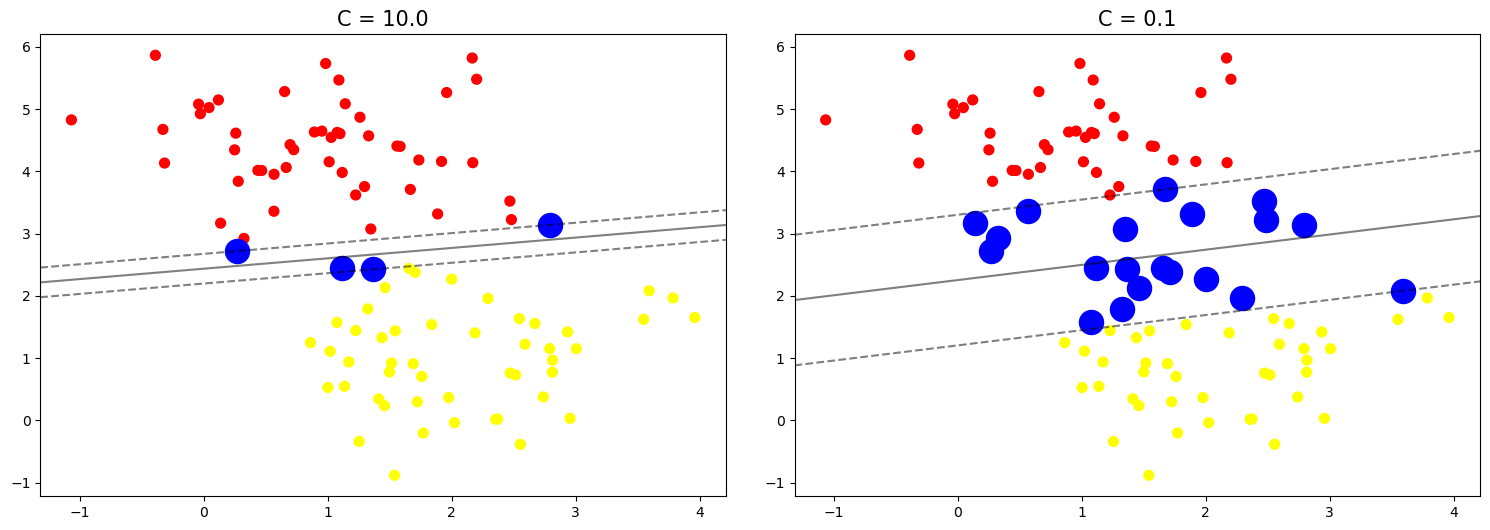

In [55]:
fig, ax = plt.subplots(1,2, figsize=(16,6))
fig.subplots_adjust(left = 0.05, right = 0.95, wspace=0.1)

for ax_i, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel="linear", C=C)
    model.fit(X,Y)
    ax_i.scatter(X[:,0], X[:,1], c = Y, s=50, cmap="autumn")
    plt_svc(model, ax_i)
    ax_i.set_title("C = {0:.1f}".format(C), size = 15)